# What do the flexible models learn, and how stable is it?

Distinguish curved single-feature response shapes from interactions. These plots describe fitted log-odds associations, not physiological injury thresholds or causal mechanisms.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
while not (ROOT/'src/injury_analysis').exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.injury_analysis.ucl_nonlinear_common import OUT, CACHE, CFG, read_table
pd.set_option('display.max_columns',20)
protocol=json.loads((OUT/'frozen_protocol.json').read_text())
def show(name,n=25):display(read_table(name).head(n))
def plot(name):display(Image(filename=str(OUT/'figures'/(name+'.png')),width=1150))


In [2]:
from src.injury_analysis.ucl_nonlinear_analysis import run_analysis
from src.injury_analysis.ucl_nonlinear_probes import run_probes
from src.injury_analysis.ucl_nonlinear_diagnostics import run_diagnostics
run_analysis();run_probes();run_diagnostics()
ref=pd.read_parquet(CACHE/'training_effect_reference.parquet')
display(pd.Series({'reference_outings':len(ref),'reference_pitchers':ref.pitcher_id.nunique(),'maximum_outings_per_pitcher':ref.groupby('pitcher_id').size().max(),'latest_reference_date':ref.game_date.max()}))

reference_outings                             4000
reference_pitchers                            1076
maximum_outings_per_pitcher                      5
latest_reference_date          2021-09-30 00:00:00
dtype: object

## Training-supported local effects

ALE uses observed values within training-reference quantile bins. The reference caps each pitcher at five outings; no outcomes choose the sample. Curves use centered local log-odds differences. Shading is the range of eight whole-pitcher refits, not a confidence interval. Missing source values do not enter the plotted observed-value distribution.

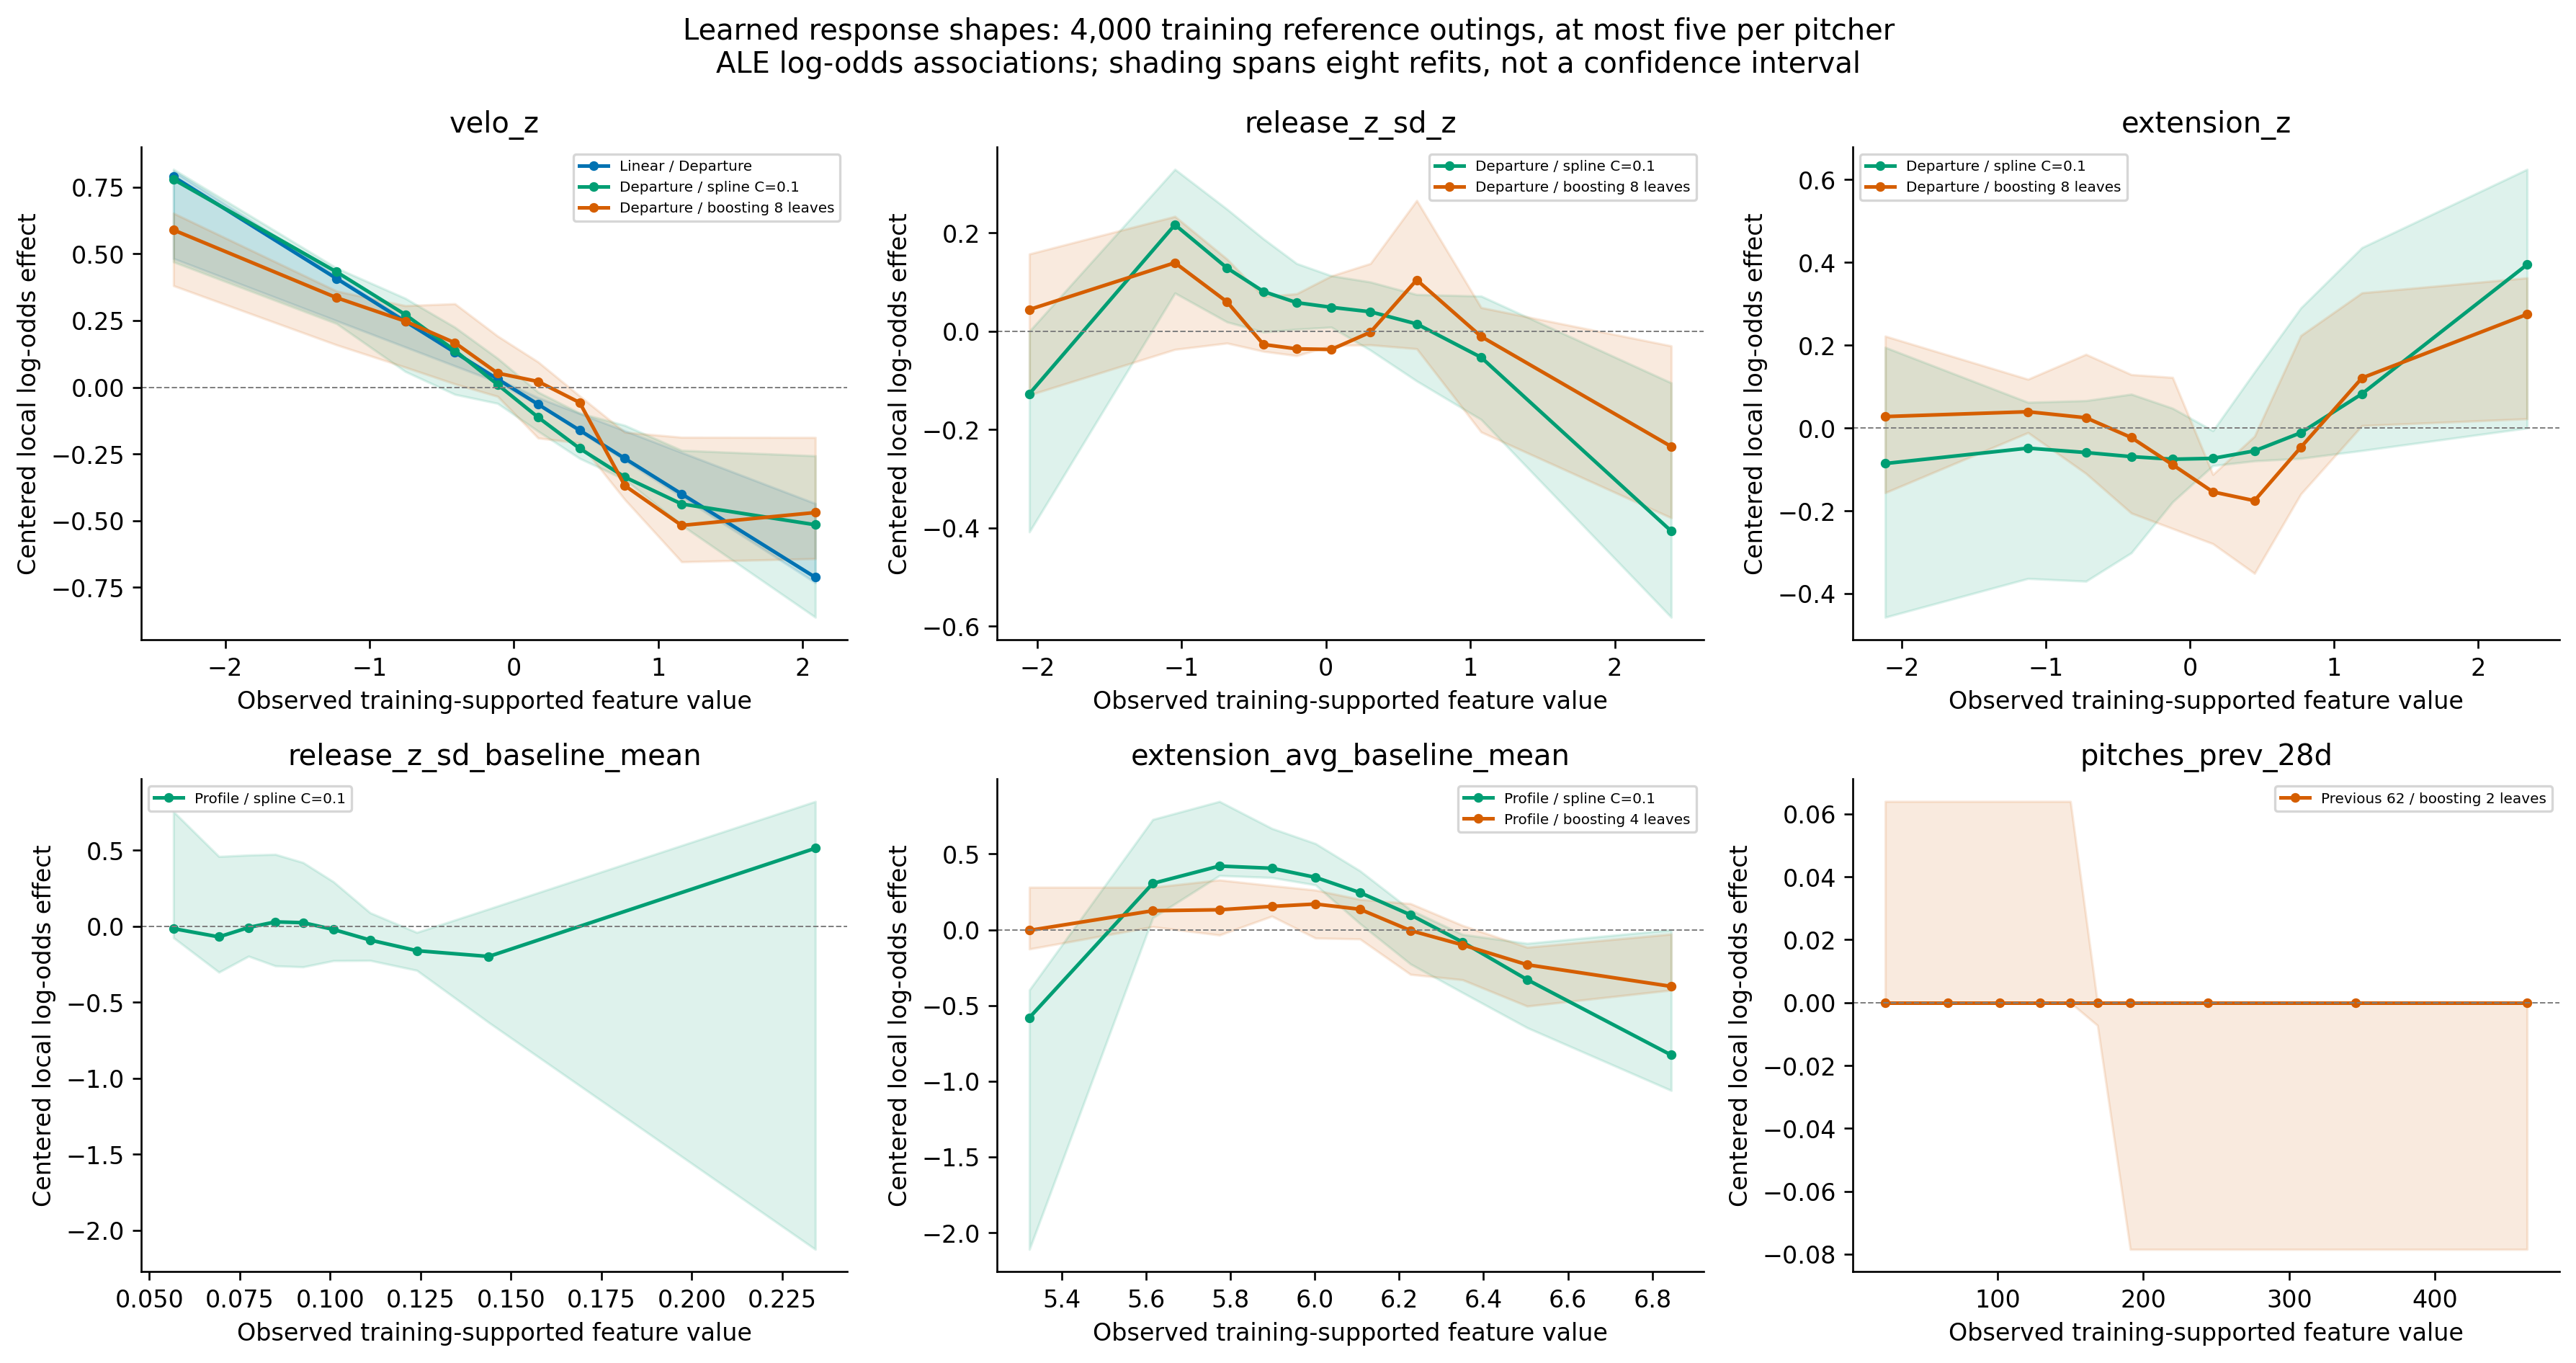

,model_id,feature,median_refit_shape_correlation,original_effect_range,refit_effect_range_min,refit_effect_range_max
0,Departure__Boosting__8,extension_z,0.666520,0.450077,0.317283,0.713667
1,Departure__Boosting__8,release_x_sd_z,0.402664,0.095924,0.213097,0.442010
2,Departure__Boosting__8,release_x_z,0.837441,0.670606,0.440886,0.992358
3,Departure__Boosting__8,release_z_sd_z,0.761728,0.373763,0.131579,0.571124
4,Departure__Boosting__8,release_z_z,0.901925,0.393097,0.261902,0.600986
5,Departure__Boosting__8,spin_z,0.320958,0.180229,0.147272,0.513162
6,Departure__Boosting__8,velo_z,0.957753,1.107472,0.632918,1.217313
7,Departure__Boosting__8,zone_pct_z,0.627592,0.143865,0.165153,0.641318
8,Departure__Spline__0p1,extension_z,0.704005,0.480390,0.267482,1.081742
9,Departure__Spline__0p1,release_x_sd_z,0.319486,0.201749,0.195147,0.760480


In [3]:
plot('04_nonlinear_effect_curves')
show('effect_shape_stability',n=20)

**Interpretation:** The lower-velocity/higher-risk direction is already present in the linear model. Flexible release, extension and spin curves do not consistently improve ranking or warning. Historical profile release variability and extension can have curved effects, but broad refit ranges and concentrated AP limit interpretation. A flat workload curve in a selected stump model means that fit did not use that measurement; it does not prove workload is irrelevant.

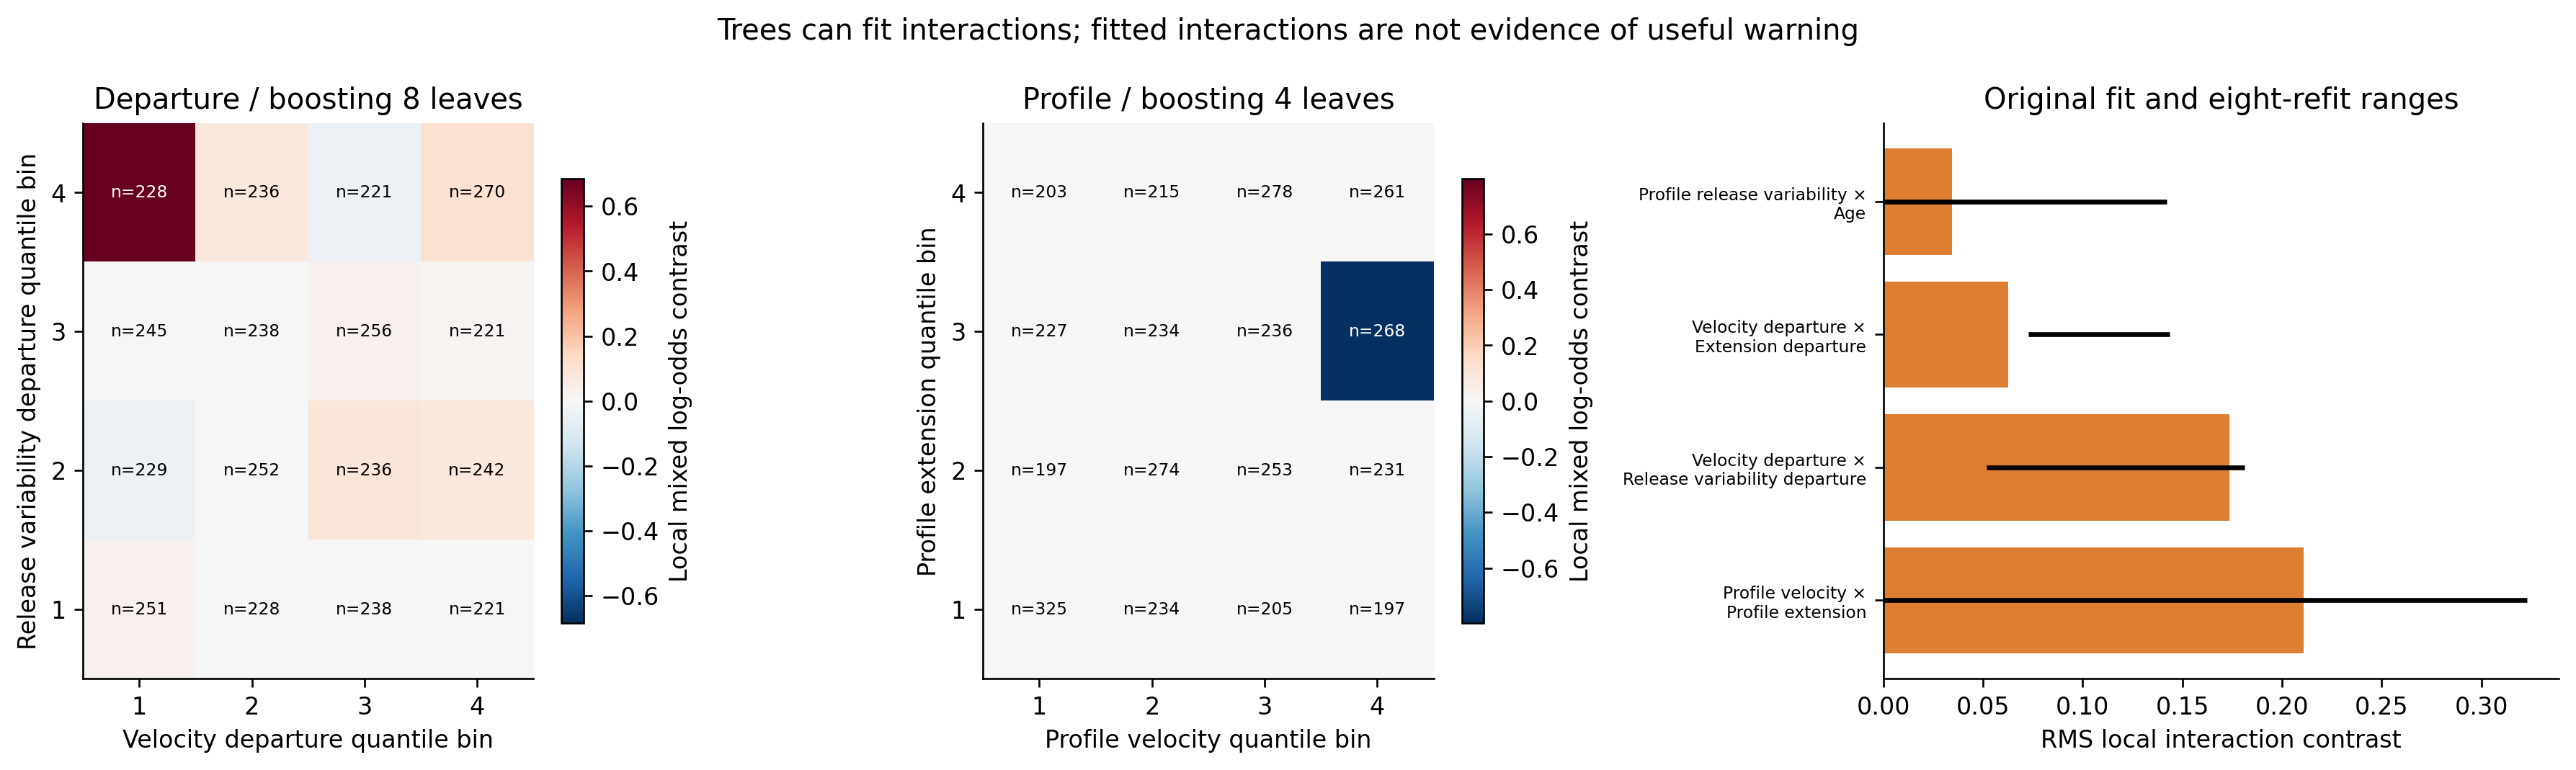

,model_id,left,right,supported_cells,original_rms,refit_rms_mean,refit_rms_min,refit_rms_max,median_map_correlation,mean_cell_sign_agreement
0,Departure__Boosting__8,velo_z,extension_z,16,6.252740e-02,1.031967e-01,7.261578e-02,1.436542e-01,0.399987,0.589178
1,Departure__Boosting__8,velo_z,release_z_sd_z,16,1.737255e-01,1.099263e-01,5.181862e-02,1.811205e-01,0.664661,0.602243
2,Departure__Spline__0p1,velo_z,extension_z,16,5.359094e-17,6.565545e-17,3.563414e-17,1.064305e-16,NaN,NaN
3,Departure__Spline__0p1,velo_z,release_z_sd_z,16,6.470523e-17,6.508863e-17,3.927485e-17,1.178727e-16,NaN,NaN
4,Linear|Departure,velo_z,extension_z,16,4.540636e-17,6.888033e-17,4.858031e-17,1.217120e-16,NaN,NaN
5,Linear|Departure,velo_z,release_z_sd_z,16,7.700680e-17,1.143246e-16,4.832800e-17,3.205600e-16,NaN,NaN
6,Linear|Stable 62,velo_z,extension_z,16,4.597191e-17,6.078264e-17,4.793129e-17,8.487793e-17,NaN,NaN
7,Previous_62__Boosting__2,velo_z,avg_fb_velo_baseline_mean,16,2.605216e-18,1.637568e-17,0.000000e+00,9.020087e-17,NaN,NaN
8,Previous_62__Boosting__2,velo_z,extension_z,16,0.000000e+00,4.012366e-19,0.000000e+00,2.737204e-18,NaN,NaN
9,Previous_62__Boosting__2,velo_z,pitches_prev_28d,16,0.000000e+00,2.128931e-18,0.000000e+00,1.612430e-17,NaN,NaN


In [4]:
plot('05_interactions_and_stability')
show('interaction_stability',n=25)

Local four-corner log-odds contrasts cancel additive main effects, including curved GAM effects. They are a local nonadditivity diagnostic, **not** full second-order ALE. Cells require ≥40 reference observations and ≥15 pitchers. Selected profile+departure and previous-62 boosting models are stumps and therefore have zero log-odds interactions. Other tree fits learn nonadditivity, but this alone does not show incremental predictive value. Profile-only pairs are supplemental interpretation probes, not new model selection.

In [5]:
show('permutation_summary',n=25)
show('permutation_stability',n=25)

,model_id,feature,mean,sd
0,Departure__Boosting__8,release_z_sd_z,0.000607,0.000205
1,Departure__Boosting__8,extension_z,0.000465,0.000226
2,Departure__Boosting__8,release_z_z,0.000367,0.000123
3,Departure__Boosting__8,spin_z,0.000126,0.000116
4,Departure__Boosting__8,zone_pct_z,-0.000054,0.000045
5,Departure__Boosting__8,release_x_sd_z,-0.000063,0.000166
6,Departure__Boosting__8,velo_z,-0.000298,0.001706
7,Departure__Boosting__8,release_x_z,-0.000912,0.000693
8,Departure__Spline__0p1,release_z_sd_z,0.000386,0.000138
9,Departure__Spline__0p1,extension_z,0.000383,0.000149


,model_id,feature,mean,sd,positive_fraction,minimum,maximum
0,Departure__Boosting__8,extension_z,0.000217,0.000206,0.875,-0.000156,0.000514
1,Departure__Boosting__8,release_x_sd_z,0.000146,0.000248,0.750,-0.000231,0.000496
2,Departure__Boosting__8,release_x_z,-0.000919,0.000682,0.000,-0.002387,-0.000243
3,Departure__Boosting__8,release_z_sd_z,0.000112,0.000370,0.625,-0.000405,0.000678
4,Departure__Boosting__8,release_z_z,0.000272,0.000347,0.750,-0.000171,0.000793
5,Departure__Boosting__8,spin_z,0.000005,0.000234,0.625,-0.000397,0.000289
6,Departure__Boosting__8,velo_z,0.000597,0.000517,1.000,0.000108,0.001770
7,Departure__Boosting__8,zone_pct_z,0.000049,0.000267,0.500,-0.000216,0.000633
8,Departure__Spline__0p1,extension_z,0.000267,0.000369,0.875,-0.000414,0.000813
9,Departure__Spline__0p1,release_x_sd_z,0.000164,0.000294,0.625,-0.000158,0.000729


Permutation is marginal and may break correlated predictor relationships. Importance is not causal or unique information. Stable-looking curves are not enough if performance depends on a few pitchers.

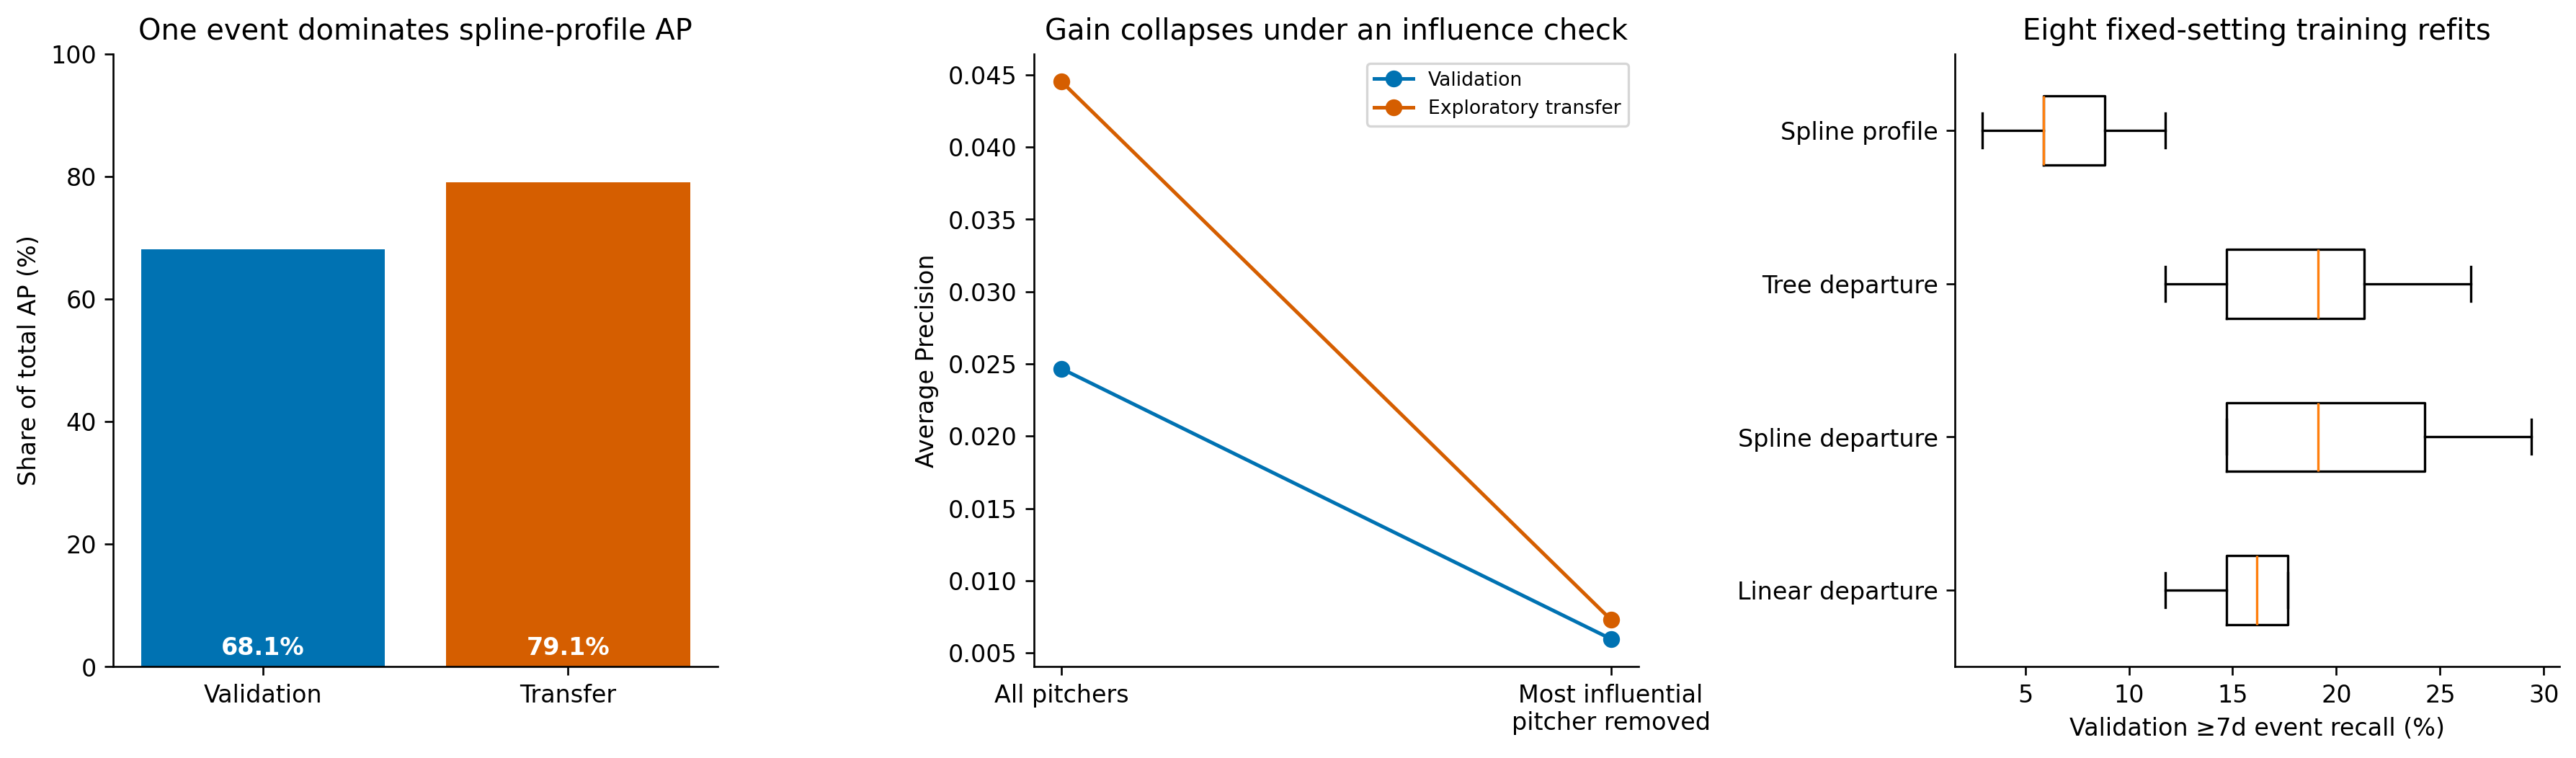

,pitcher_id,dynamic_next_event_id,positive_rows,ap_contribution,maximum_score,fraction_total_ap,model_id,partition
284,679885,e27e13fce8d41eb795ba9670d008fb45,5,0.035211,0.046121,0.791066,Profile__Spline__0p1,test
283,678495,864c106cc759eae1e8437e84e2a88b01,8,0.003957,0.023077,0.088901,Profile__Spline__0p1,test
288,695549,223ecfdd6544d6142bf28095bae4230a,6,0.000663,0.011938,0.014892,Profile__Spline__0p1,test
101,528748,00063184096cfacffd696681ef4d4744,6,0.016792,0.071863,0.680948,Profile__Spline__0p1,validation
121,669622,fae28b12535c521d62c9956ae54987a5,6,0.002104,0.022632,0.085319,Profile__Spline__0p1,validation
109,642585,8c945a320728dd144f1dccaa07472b52,11,0.000948,0.009958,0.038436,Profile__Spline__0p1,validation


In [6]:
plot('06_composition_and_refit_uncertainty')
g=read_table('event_ap_contributions')
display(g.loc[g.model_id.eq(protocol['ranking_leaders']['Spline'])].sort_values(['partition','fraction_total_ap'],ascending=[True,False]).groupby('partition').head(3))

In [7]:
g=read_table('leave_one_injured_pitcher_out')
display(g.loc[g.model_id.eq(protocol['ranking_leaders']['Spline'])].sort_values(['partition','ap_drop_without_pitcher'],ascending=[True,False]).groupby('partition').head(3))
show('high_influence_pitcher_profiles',n=15)

,partition,model_id,excluded_pitcher_id,removed_positive_rows,excluded_positive_events,original_ap,ap_without_pitcher,ap_drop_without_pitcher
284,test,Profile__Spline__0p1,679885,5,1,0.044511,0.007309,0.037202
283,test,Profile__Spline__0p1,678495,8,1,0.044511,0.041938,0.002573
281,test,Profile__Spline__0p1,675911,2,1,0.044511,0.044974,-0.000463
101,validation,Profile__Spline__0p1,528748,6,1,0.024660,0.005976,0.018683
121,validation,Profile__Spline__0p1,669622,6,1,0.024660,0.022697,0.001962
111,validation,Profile__Spline__0p1,656818,3,1,0.024660,0.024502,0.000158


,partition,model_id,pitcher_id,injury_event_id,player_name,feature,positive_row_mean,training_percentile,minimum_prior_outings,fraction_total_ap
0,validation,Linear|Stable 62,642585,8c945a320728dd144f1dccaa07472b52,Félix Bautista,acute_chronic_pitch_ratio,1.146523,0.262071,110,0.275036
1,validation,Linear|Stable 62,642585,8c945a320728dd144f1dccaa07472b52,Félix Bautista,age_at_appearance,28.146929,0.408796,110,0.275036
2,validation,Linear|Stable 62,642585,8c945a320728dd144f1dccaa07472b52,Félix Bautista,appearances_prev_14d,4.545455,0.611709,110,0.275036
3,validation,Linear|Stable 62,642585,8c945a320728dd144f1dccaa07472b52,Félix Bautista,avg_fb_velo_baseline_sd,0.610228,0.178879,110,0.275036
4,validation,Linear|Stable 62,642585,8c945a320728dd144f1dccaa07472b52,Félix Bautista,calendar_month,7.818182,0.760638,110,0.275036
5,validation,Linear|Stable 62,642585,8c945a320728dd144f1dccaa07472b52,Félix Bautista,ch_avg_velocity_prev_5,NaN,0.000000,110,0.275036
6,validation,Linear|Stable 62,642585,8c945a320728dd144f1dccaa07472b52,Félix Bautista,ch_release_x_avg_prev_10,NaN,0.000000,110,0.275036
7,validation,Linear|Stable 62,642585,8c945a320728dd144f1dccaa07472b52,Félix Bautista,ch_usage_pct_prev_3,0.000000,0.334356,110,0.275036
8,validation,Linear|Stable 62,642585,8c945a320728dd144f1dccaa07472b52,Félix Bautista,ch_vertical_movement_avg,NaN,0.000000,110,0.275036
9,validation,Linear|Stable 62,642585,8c945a320728dd144f1dccaa07472b52,Félix Bautista,cu_avg_velocity_prev_5,NaN,0.000000,110,0.275036


**Composition sensitivity:** One event contributes 68% of validation spline-profile AP; another contributes 79% of transfer AP. Removing its pitcher lowers AP to 0.00598 and 0.00731, respectively. These cases should remain in the dataset. The diagnostic changes the interpretation of aggregate AP rather than selecting a convenient cohort.